# Retail Demand Forecasting & Inventory Intelligence

## 1. Data Exploration

Objective: Explore historical retail sales data, understand its structure,
identify patterns, and check data quality before building forecasting models.

## 2. Import Libraries

Import the required Python libraries for data analysis, numerical operations,
visualization and file handling.

In [139]:
# imported libraries for analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

## 3. Data Loading

Load the historical retail sales dataset for further analysis.

## 4. Dataset Inspection

Check the dataset dimensions, columns and data types.

In [140]:
# load sales data

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

TRAIN_DATA_PATH = PROJECT_ROOT / "data" / "train.csv"

train_df = pd.read_csv(TRAIN_DATA_PATH)

print("Dataset loaded successfully!")
display(train_df.head())

Dataset loaded successfully!


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


## 4. Dataset Inspection

Check the dataset dimensions, columns and data types.

In [141]:
# check dataset structure

print("Dataset Shape:", train_df.shape)

print("\nColumn Information:")
train_df.info()

print("\nFirst 5 Records:")
display(train_df.head())

Dataset Shape: (913000, 4)

Column Information:
<class 'pandas.DataFrame'>
RangeIndex: 913000 entries, 0 to 912999
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype
---  ------  --------------   -----
 0   date    913000 non-null  str  
 1   store   913000 non-null  int64
 2   item    913000 non-null  int64
 3   sales   913000 non-null  int64
dtypes: int64(3), str(1)
memory usage: 36.6 MB

First 5 Records:


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


## 5. Data Quality Checks

Check missing values, duplicate records and data consistency.

In [142]:
# check missing values and duplicates

print("Missing Values:")
print(train_df.isnull().sum())

print("\nDuplicate Records:", train_df.duplicated().sum())

Missing Values:
date     0
store    0
item     0
sales    0
dtype: int64

Duplicate Records: 0


In [143]:
# check available date range

print("Start Date:", train_df["date"].min())
print("End Date:", train_df["date"].max())

Start Date: 2013-01-01
End Date: 2017-12-31


In [144]:
# check number of stores and products

print("Total Stores:", train_df["store"].nunique())
print("Total Products:", train_df["item"].nunique())

Total Stores: 10
Total Products: 50


In [145]:
# check available store and product ids

print("Store IDs:", sorted(train_df["store"].unique()))
print("Product IDs:", sorted(train_df["item"].unique()))

Store IDs: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]
Product IDs: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(37), np.int64(38), np.int64(39), np.int64(40), np.int64(41), np.int64(42), np.int64(43), np.int64(44), np.int64(45), np.int64(46), np.int64(47), np.int64(48), np.int64(49), np.int64(50)]


In [146]:
# check store-product combinations

records_per_combination = train_df.groupby(
    ["store", "item"]
).size()

print("Total Combinations:", records_per_combination.shape[0])
print("Minimum Records:", records_per_combination.min())
print("Maximum Records:", records_per_combination.max())

Total Combinations: 500
Minimum Records: 1826
Maximum Records: 1826


In [147]:
# check sales distribution

display(train_df["sales"].describe())

print("Zero Sales:", (train_df["sales"] == 0).sum())
print("Negative Sales:", (train_df["sales"] < 0).sum())

count    913000.000000
mean         52.250287
std          28.801144
min           0.000000
25%          30.000000
50%          47.000000
75%          70.000000
max         231.000000
Name: sales, dtype: float64

Zero Sales: 1
Negative Sales: 0


## 6. Date Feature Engineering

Convert dates and extract calendar features for sales analysis.

In [148]:
# convert date column to datetime

train_df["date"] = pd.to_datetime(train_df["date"])

print(train_df["date"].dtype)

datetime64[us]


In [149]:
# add year, month and weekday columns

train_df["year"] = train_df["date"].dt.year
train_df["month"] = train_df["date"].dt.month
train_df["day"] = train_df["date"].dt.day
train_df["day_of_week"] = train_df["date"].dt.dayofweek

display(train_df[["date", "year", "month", "day", "day_of_week"]].head())

C:\Users\Saurabh Prajapati\AppData\Local\Temp\ipykernel_8784\3113833920.py:6: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  train_df["day_of_week"] = train_df["date"].dt.dayofweek


,date,year,month,day,day_of_week
0,2013-01-01,2013,1,1,1
1,2013-01-02,2013,1,2,2
2,2013-01-03,2013,1,3,3
3,2013-01-04,2013,1,4,4
4,2013-01-05,2013,1,5,5


## 7. Sales Trend Analysis

Analyze sales across weekdays, months and years to identify demand patterns.

In [150]:
# average sales for each weekday

weekday_sales = train_df.groupby("day_of_week")["sales"].mean()

weekday_names = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday"
}

weekday_sales.index = weekday_sales.index.map(weekday_names)

display(weekday_sales)

day_of_week
Monday       41.429638
Tuesday      48.225908
Wednesday    48.368506
Thursday     51.723218
Friday       55.157249
Saturday     58.662697
Sunday       62.143333
Name: sales, dtype: float64

In [151]:
# average sales for each month

monthly_sales = train_df.groupby("month")["sales"].mean()

display(monthly_sales)

month
1     35.524503
2     39.378397
3     47.305574
4     55.152893
5     59.128219
6     63.025480
7     66.998619
8     59.105226
9     55.072760
10    51.193806
11    55.218080
12    39.365265
Name: sales, dtype: float64

In [152]:
# average sales for each year

yearly_sales = train_df.groupby("year")["sales"].mean()

display(yearly_sales)

year
2013    43.513660
2014    50.057436
2015    52.256915
2016    56.596503
2017    58.815014
Name: sales, dtype: float64

In [153]:
# count records for each year

yearly_records = train_df.groupby("year").size()

display(yearly_records)

year
2013    182500
2014    182500
2015    182500
2016    183000
2017    182500
dtype: int64

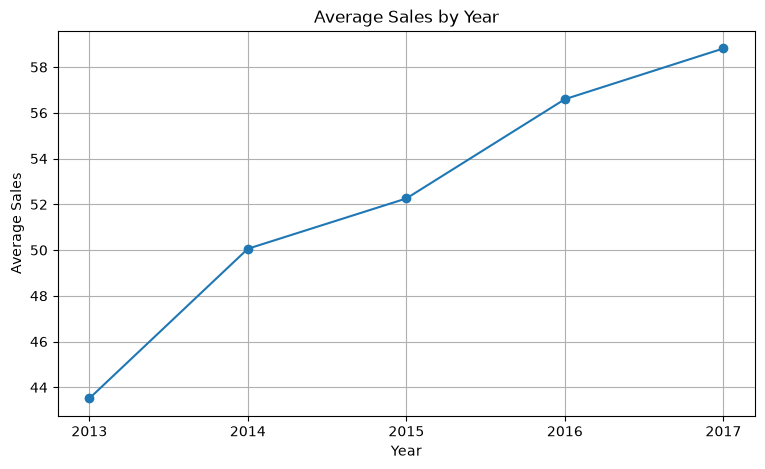

In [154]:
# yearly sales trend

plt.figure(figsize=(9, 5))

plt.plot(yearly_sales.index, yearly_sales.values, marker="o")

plt.title("Average Sales by Year")
plt.xlabel("Year")
plt.ylabel("Average Sales")
plt.xticks(yearly_sales.index)
plt.grid(True)

plt.show()

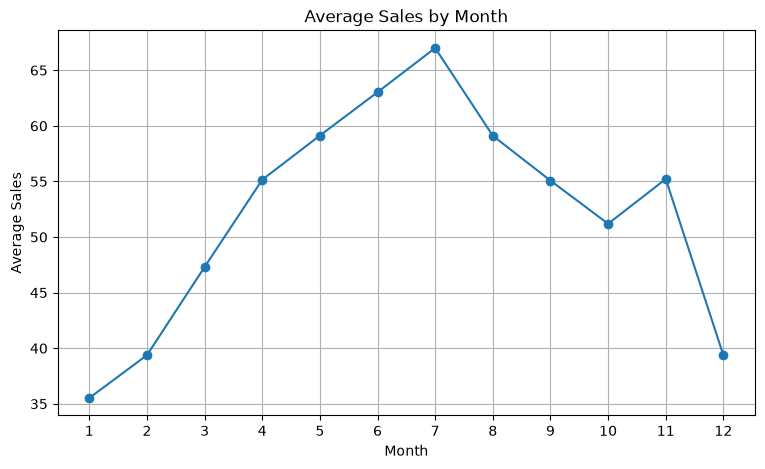

In [155]:
# monthly sales trend

plt.figure(figsize=(9, 5))

plt.plot(monthly_sales.index, monthly_sales.values, marker="o")

plt.title("Average Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Sales")
plt.xticks(range(1, 13))
plt.grid(True)

plt.show()

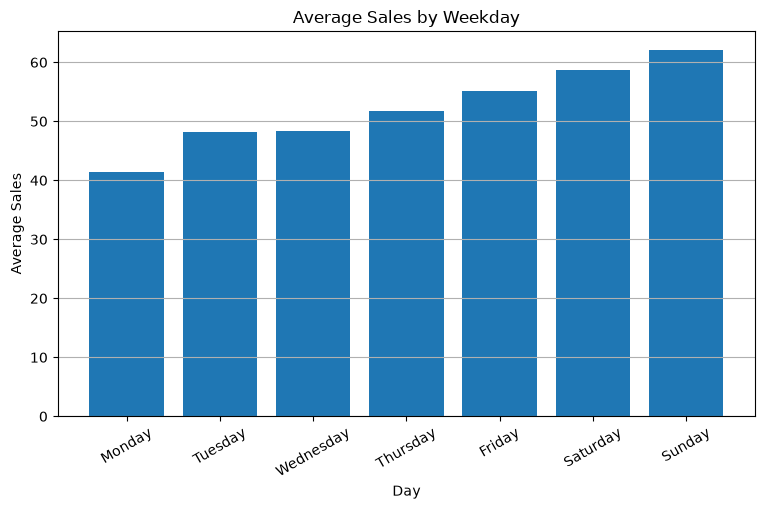

In [156]:
# weekday sales comparison

plt.figure(figsize=(9, 5))

plt.bar(weekday_sales.index, weekday_sales.values)

plt.title("Average Sales by Weekday")
plt.xlabel("Day")
plt.ylabel("Average Sales")
plt.xticks(rotation=30)
plt.grid(axis="y")

plt.show()

## 8. Store and Product Performance

Compare sales across stores and products to identify high-performing and low-performing segments.

In [157]:
# average sales by store

store_sales = train_df.groupby("store")["sales"].mean().sort_values(ascending=False)

display(store_sales)

store
2     67.033165
8     64.142048
3     59.530602
10    58.709288
9     55.049025
4     54.902946
1     47.268379
5     39.770164
6     39.733516
7     36.363735
Name: sales, dtype: float64

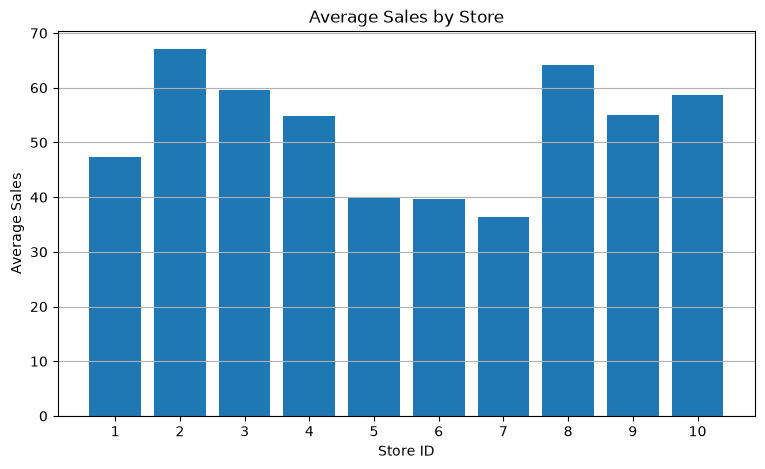

In [158]:
# store sales comparison

plt.figure(figsize=(9, 5))

plt.bar(store_sales.index, store_sales.values)

plt.title("Average Sales by Store")
plt.xlabel("Store ID")
plt.ylabel("Average Sales")
plt.xticks(store_sales.index)
plt.grid(axis="y")

plt.show()

In [159]:
# average sales by product

product_sales = train_df.groupby("item")["sales"].mean().sort_values(ascending=False)

display(product_sales)

item
15    88.030778
28    87.881325
13    84.316594
18    84.275794
25    80.686418
45    80.584173
38    80.521906
22    80.502245
36    77.028916
8     76.950055
10    73.227437
11    69.656353
12    69.634940
29    69.618839
33    69.560953
24    66.044633
50    65.882202
35    65.801807
14    58.681873
31    58.644304
46    58.639869
2     58.574151
7     58.531051
6     58.503888
9     51.389869
48    51.352848
43    51.294359
26    47.644085
20    47.515936
32    43.981763
39    43.883406
19    40.355531
30    40.337021
21    40.317087
42    36.688116
3     36.642223
17    32.994852
44    29.398193
49    29.335323
23    29.297864
37    29.258379
40    29.249398
34    25.735761
16    25.656079
27    22.049726
4     22.010241
47    22.003341
41    22.002136
1     21.981599
5     18.358708
Name: sales, dtype: float64

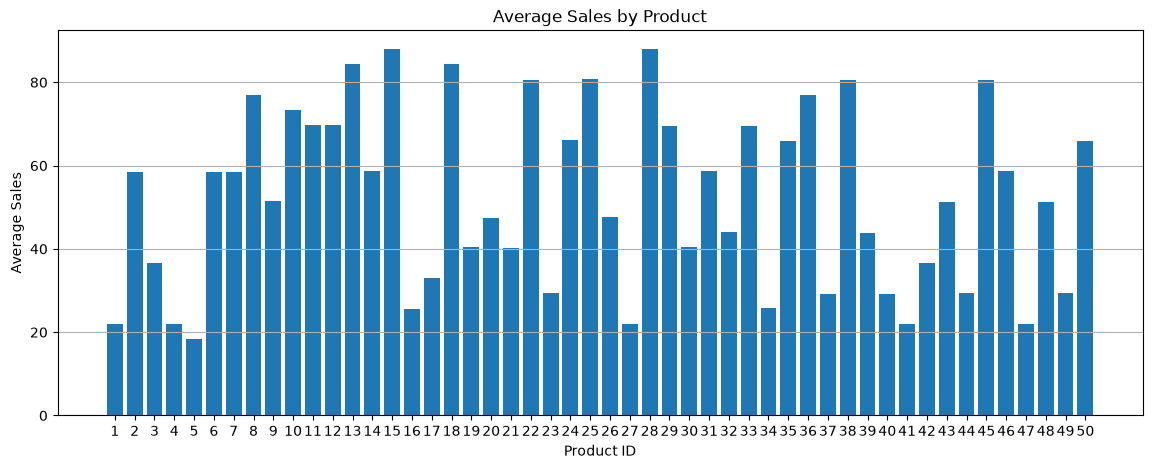

In [160]:
# product sales comparison

plt.figure(figsize=(14, 5))

plt.bar(product_sales.index, product_sales.values)

plt.title("Average Sales by Product")
plt.xlabel("Product ID")
plt.ylabel("Average Sales")
plt.xticks(range(1, 51))
plt.grid(axis="y")

plt.show()

In [161]:
# top 10 products by average sales

top_products = product_sales.head(10)

display(top_products)

item
15    88.030778
28    87.881325
13    84.316594
18    84.275794
25    80.686418
45    80.584173
38    80.521906
22    80.502245
36    77.028916
8     76.950055
Name: sales, dtype: float64

In [162]:
# bottom 10 products by average sales

bottom_products = product_sales.tail(10).sort_values()

display(bottom_products)

item
5     18.358708
1     21.981599
41    22.002136
47    22.003341
4     22.010241
27    22.049726
16    25.656079
34    25.735761
40    29.249398
37    29.258379
Name: sales, dtype: float64

## 9. Store-Product Performance

Analyze sales for individual store-product combinations to identify the strongest and weakest combinations.

In [163]:
# average sales for each store-product pair

store_product_sales = (
    train_df.groupby(["store", "item"])["sales"]
    .mean()
    .reset_index()
)

display(store_product_sales.head(10))

,store,item,sales
0,1,1,19.971522
1,1,2,53.148959
2,1,3,33.208105
3,1,4,19.956188
4,1,5,16.612815
5,1,6,53.060789
6,1,7,52.783680
7,1,8,69.472070
8,1,9,46.504929
9,1,10,66.354326


In [164]:
# top 10 store-product combinations

top_store_products = store_product_sales.sort_values(
    by="sales", ascending=False
).head(10)

display(top_store_products)

,store,item,sales
77,2,28,112.638007
64,2,15,112.578861
67,2,18,108.117196
364,8,15,108.047645
62,2,13,107.903067
377,8,28,107.813253
367,8,18,103.820372
362,8,13,103.819825
74,2,25,103.426068
94,2,45,103.381161


In [165]:
# bottom 10 store-product combinations

bottom_store_products = store_product_sales.sort_values(
    by="sales", ascending=True
).head(10)

display(bottom_store_products)

,store,item,sales
304,7,5,12.733844
254,6,5,13.893209
204,5,5,14.086528
300,7,1,15.159365
326,7,27,15.213582
303,7,4,15.358160
340,7,41,15.471522
346,7,47,15.479189
290,6,41,16.607338
4,1,5,16.612815


## 10. Seasonal Patterns and Sales Variability

Compare monthly sales across different years and examine how sales vary across products and stores.

In [166]:
# monthly sales across different years

monthly_yearly_sales = train_df.pivot_table(
    index="month",
    columns="year",
    values="sales",
    aggfunc="mean"
)

display(monthly_yearly_sales.round(2))

year,2013,2014,2015,2016,2017
month,,,,,
1,29.35,33.93,35.65,38.87,39.83
2,32.82,37.79,39.38,42.41,44.38
3,39.83,45.44,47.16,51.02,53.08
4,45.48,52.59,54.96,60.13,62.59
5,49.24,56.96,59.80,63.79,65.85
6,53.04,60.46,62.48,68.18,70.97
7,55.22,63.81,66.93,73.47,75.57
8,49.47,57.14,59.38,63.32,66.22
9,45.99,52.34,54.89,59.79,62.35


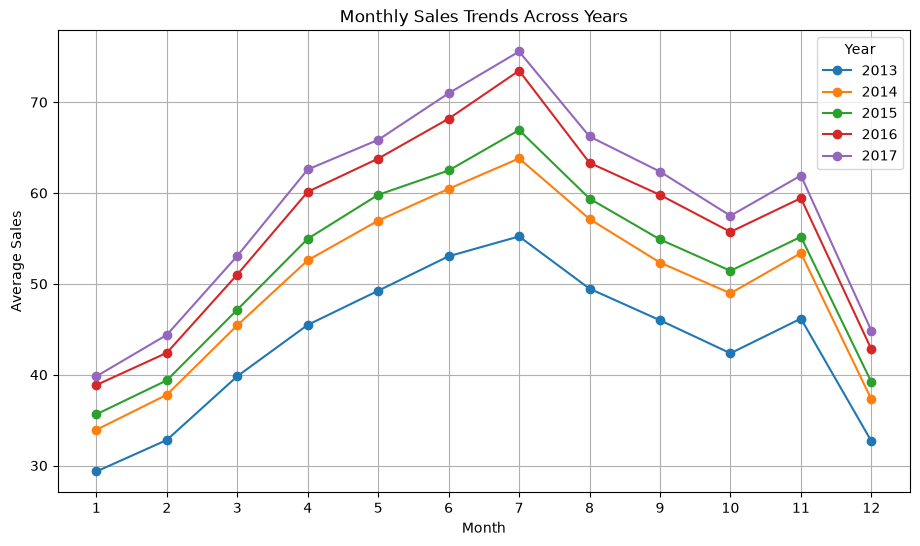

In [167]:
# compare monthly sales across years

monthly_yearly_sales.plot(
    figsize=(11, 6),
    marker="o"
)

plt.title("Monthly Sales Trends Across Years")
plt.xlabel("Month")
plt.ylabel("Average Sales")
plt.xticks(range(1, 13))
plt.grid(True)
plt.legend(title="Year")

plt.show()

In [168]:
# check sales variation by product

product_sales_variation = train_df.groupby("item")["sales"].agg(
    ["mean", "std", "min", "max"]
)

display(product_sales_variation.round(2))

,mean,std,min,max
item,,,,
1,21.98,8.47,1,59
2,58.57,20.09,9,150
3,36.64,13.18,7,104
4,22.01,8.40,0,66
5,18.36,7.27,1,50
6,58.50,20.17,11,148
7,58.53,20.15,11,141
8,76.95,26.13,15,181
9,51.39,17.79,6,134


In [169]:
# sales variation by store

store_sales_variation = train_df.groupby("store")["sales"].agg(
    ["mean", "std", "min", "max"]
)

display(store_sales_variation.round(2))

,mean,std,min,max
store,,,,
1,47.27,24.01,1,155
2,67.03,33.60,3,231
3,59.53,29.97,3,196
4,54.90,27.73,4,186
5,39.77,20.37,2,130
6,39.73,20.31,0,134
7,36.36,18.68,1,122
8,64.14,32.23,4,204
9,55.05,27.83,4,195


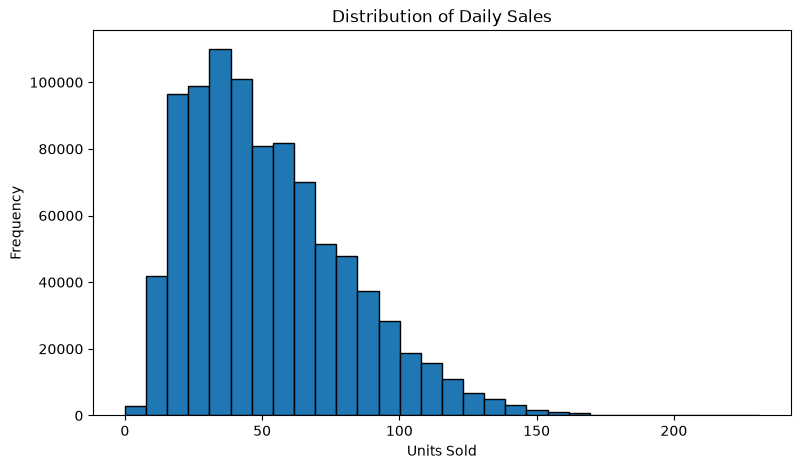

In [170]:
# sales distribution

plt.figure(figsize=(9, 5))

plt.hist(train_df["sales"], bins=30, edgecolor="black")

plt.title("Distribution of Daily Sales")
plt.xlabel("Units Sold")
plt.ylabel("Frequency")

plt.show()

## 11. Overall Sales Trends

Analyze total daily and monthly sales across all stores and products to understand the overall demand trend.

In [171]:
# total sales across all stores and products each day

daily_sales = train_df.groupby("date")["sales"].sum()

display(daily_sales.head(10))

date
2013-01-01    13696
2013-01-02    13678
2013-01-03    14488
2013-01-04    15677
2013-01-05    16237
2013-01-06    17291
2013-01-07    11769
2013-01-08    13560
2013-01-09    13878
2013-01-10    14642
Name: sales, dtype: int64

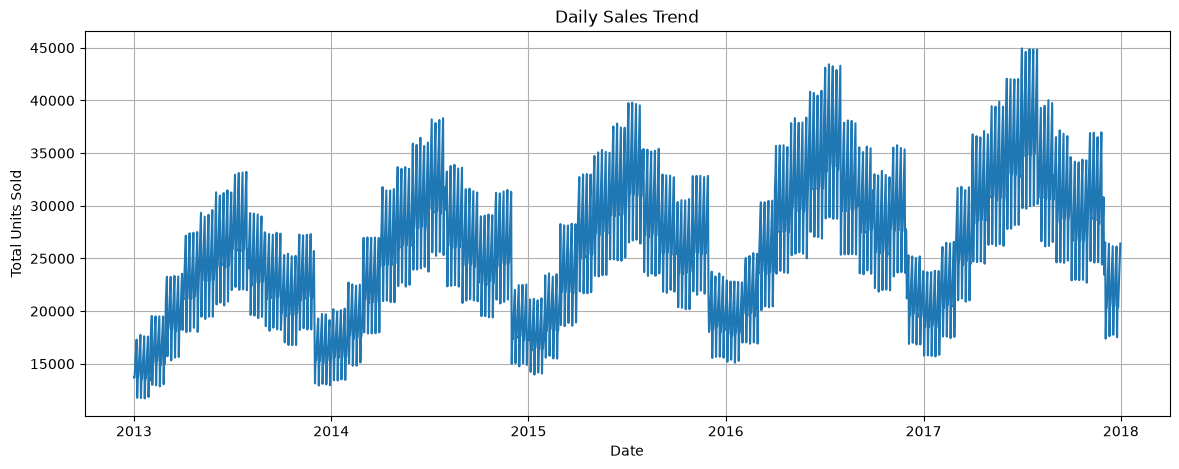

In [172]:
# daily sales trend

plt.figure(figsize=(14, 5))

plt.plot(daily_sales.index, daily_sales.values)

plt.title("Daily Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")
plt.grid(True)

plt.show()

In [173]:
# monthly total sales

monthly_total_sales = daily_sales.resample("ME").sum()

display(monthly_total_sales.head(12))

date
2013-01-31    454904
2013-02-28    459417
2013-03-31    617382
2013-04-30    682274
2013-05-31    763242
2013-06-30    795597
2013-07-31    855922
2013-08-31    766761
2013-09-30    689907
2013-10-31    656587
2013-11-30    692643
2013-12-31    506607
Freq: ME, Name: sales, dtype: int64

## 12. Feature Engineering for Demand Forecasting

Create time-based and historical sales features to help machine learning models learn demand patterns and predict future sales.

In [174]:
# sort data by store, item and date
model_df = train_df.sort_values(["store", "item", "date"]).copy()

display(model_df.head())

,date,store,item,sales,year,month,day,day_of_week
0,2013-01-01,1,1,13,2013,1,1,1
1,2013-01-02,1,1,11,2013,1,2,2
2,2013-01-03,1,1,14,2013,1,3,3
3,2013-01-04,1,1,13,2013,1,4,4
4,2013-01-05,1,1,10,2013,1,5,5


In [175]:
# create 7-day lag feature
model_df["lag_7"] = model_df.groupby(["store", "item"])["sales"].shift(7)

display(model_df[["date", "store", "item", "sales", "lag_7"]].head(12))

,date,store,item,sales,lag_7
0,2013-01-01,1,1,13,NaN
1,2013-01-02,1,1,11,NaN
2,2013-01-03,1,1,14,NaN
3,2013-01-04,1,1,13,NaN
4,2013-01-05,1,1,10,NaN
5,2013-01-06,1,1,12,NaN
6,2013-01-07,1,1,10,NaN
7,2013-01-08,1,1,9,13.0
8,2013-01-09,1,1,12,11.0
9,2013-01-10,1,1,9,14.0


In [176]:
# create additional lag and rolling features
groups = model_df.groupby(["store", "item"])["sales"]

model_df["lag_14"] = groups.shift(14)
model_df["lag_28"] = groups.shift(28)

model_df["rolling_mean_7"] = groups.transform(
    lambda x: x.shift(1).rolling(7).mean()
)

model_df["rolling_mean_28"] = groups.transform(
    lambda x: x.shift(1).rolling(28).mean()
)

display(model_df.head(35))

,date,store,item,sales,year,month,day,day_of_week,lag_7,lag_14,lag_28,rolling_mean_7,rolling_mean_28
0,2013-01-01,1,1,13,2013,1,1,1,NaN,NaN,NaN,NaN,NaN
1,2013-01-02,1,1,11,2013,1,2,2,NaN,NaN,NaN,NaN,NaN
2,2013-01-03,1,1,14,2013,1,3,3,NaN,NaN,NaN,NaN,NaN
3,2013-01-04,1,1,13,2013,1,4,4,NaN,NaN,NaN,NaN,NaN
4,2013-01-05,1,1,10,2013,1,5,5,NaN,NaN,NaN,NaN,NaN
5,2013-01-06,1,1,12,2013,1,6,6,NaN,NaN,NaN,NaN,NaN
6,2013-01-07,1,1,10,2013,1,7,0,NaN,NaN,NaN,NaN,NaN
7,2013-01-08,1,1,9,2013,1,8,1,13.0,NaN,NaN,11.857143,NaN
8,2013-01-09,1,1,12,2013,1,9,2,11.0,NaN,NaN,11.285714,NaN
9,2013-01-10,1,1,9,2013,1,10,3,14.0,NaN,NaN,11.428571,NaN


### 12.1 Lag and Rolling Features

Create historical sales features to capture weekly demand patterns and recent sales trends.

In [177]:
# check generated features
feature_cols = [
    "lag_7", "lag_14", "lag_28",
    "rolling_mean_7", "rolling_mean_28"
]

display(model_df[feature_cols].describe())
print("\nMissing values:")
print(model_df[feature_cols].isnull().sum())

,lag_7,lag_14,lag_28,rolling_mean_7,rolling_mean_28
count,909500.00000,906000.000000,899000.000000,909500.000000,899000.000000
mean,52.28043,52.310783,52.373607,52.299703,52.479155
std,28.81846,28.836381,28.872437,27.009716,26.811192
min,0.00000,0.000000,0.000000,5.571429,6.750000
25%,30.00000,30.000000,30.000000,30.428571,30.714286
50%,47.00000,47.000000,47.000000,47.714286,48.071429
75%,70.00000,70.000000,70.000000,69.428571,69.642857
max,231.00000,231.000000,231.000000,175.428571,164.892857



Missing values:
lag_7               3500
lag_14              7000
lag_28             14000
rolling_mean_7      3500
rolling_mean_28    14000
dtype: int64


### 12.2 Calendar Features

Capture recurring demand patterns using weekday, month and week information.

In [178]:
# create additional calendar features
model_df["week_of_year"] = model_df["date"].dt.isocalendar().week.astype(int)
model_df["is_weekend"] = (model_df["day_of_week"] >= 5).astype(int)

display(model_df[["date", "day_of_week", "month", "week_of_year", "is_weekend"]].head(10))

,date,day_of_week,month,week_of_year,is_weekend
0,2013-01-01,1,1,1,0
1,2013-01-02,2,1,1,0
2,2013-01-03,3,1,1,0
3,2013-01-04,4,1,1,0
4,2013-01-05,5,1,1,1
5,2013-01-06,6,1,1,1
6,2013-01-07,0,1,2,0
7,2013-01-08,1,1,2,0
8,2013-01-09,2,1,2,0
9,2013-01-10,3,1,2,0


### 12.3 Prepare Modeling Dataset

Remove records without sufficient historical sales data and prepare the dataset for model training.

In [179]:
# remove rows with missing historical features
model_df = model_df.dropna(
    subset=["lag_7", "lag_14", "lag_28", "rolling_mean_7", "rolling_mean_28"]
).copy()

print("Modeling dataset shape:", model_df.shape)
print("Missing values:", model_df[feature_cols].isnull().sum().sum())

display(model_df.head())

Modeling dataset shape: (899000, 15)
Missing values: 0


,date,store,item,sales,year,month,day,day_of_week,lag_7,lag_14,lag_28,rolling_mean_7,rolling_mean_28,week_of_year,is_weekend
28,2013-01-29,1,1,6,2013,1,29,1,7.0,5.0,13.0,10.428571,10.714286,5,0
29,2013-01-30,1,1,9,2013,1,30,2,9.0,7.0,11.0,10.285714,10.464286,5,0
30,2013-01-31,1,1,13,2013,1,31,3,8.0,16.0,14.0,10.285714,10.392857,5,0
31,2013-02-01,1,1,11,2013,2,1,4,14.0,7.0,13.0,11.000000,10.357143,5,0
32,2013-02-02,1,1,21,2013,2,2,5,12.0,18.0,10.0,10.571429,10.285714,5,1


### 12.4 Feature Correlation Analysis

Examine relationships between historical sales features and the target sales variable.

In [180]:
# check feature correlations
correlation_cols = [
    "sales", "lag_7", "lag_14", "lag_28",
    "rolling_mean_7", "rolling_mean_28",
    "day_of_week", "month", "week_of_year", "is_weekend"
]

correlation_matrix = model_df[correlation_cols].corr()

display(correlation_matrix["sales"].sort_values(ascending=False))

sales              1.000000
lag_7              0.928662
rolling_mean_7     0.925242
lag_14             0.920944
rolling_mean_28    0.920461
lag_28             0.905221
day_of_week        0.223990
is_weekend         0.180222
month              0.069598
week_of_year       0.066997
Name: sales, dtype: float64

## 13. Train-Validation Split

Split historical data chronologically to train forecasting models on past sales and evaluate their performance on future sales.

In [181]:
# split data by date
split_date = "2017-01-01"

train_data = model_df[model_df["date"] < split_date].copy()
valid_data = model_df[model_df["date"] >= split_date].copy()

print("Training data:", train_data.shape)
print("Validation data:", valid_data.shape)

print("\nTraining period:")
print(train_data["date"].min(), "to", train_data["date"].max())

print("\nValidation period:")
print(valid_data["date"].min(), "to", valid_data["date"].max())

Training data: (716500, 15)
Validation data: (182500, 15)

Training period:
2013-01-29 00:00:00 to 2016-12-31 00:00:00

Validation period:
2017-01-01 00:00:00 to 2017-12-31 00:00:00


## 14. Baseline Model

Establish a baseline forecast using sales from the same store and product seven days earlier. Use this as a benchmark for evaluating machine learning models.

In [182]:
# evaluate baseline forecast
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

y_true = valid_data["sales"]
y_pred = valid_data["lag_7"]

baseline_mae = mean_absolute_error(y_true, y_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_true, y_pred))

print("Baseline MAE:", round(baseline_mae, 2))
print("Baseline RMSE:", round(baseline_rmse, 2))

Baseline MAE: 8.84
Baseline RMSE: 11.6


## 15. Machine Learning Models

Train machine learning models using historical sales and calendar features to improve demand predictions.

In [183]:
# select model features
features = [
    "store", "item",
    "day_of_week", "month", "year",
    "week_of_year", "is_weekend",
    "lag_7", "lag_14", "lag_28",
    "rolling_mean_7", "rolling_mean_28"
]

X_train = train_data[features]
y_train = train_data["sales"]

X_valid = valid_data[features]
y_valid = valid_data["sales"]

print("Training features:", X_train.shape)
print("Validation features:", X_valid.shape)

Training features: (716500, 12)
Validation features: (182500, 12)


In [184]:
# train random forest model
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_valid)

rf_mae = mean_absolute_error(y_valid, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_valid, rf_predictions))

print("Random Forest MAE:", round(rf_mae, 2))
print("Random Forest RMSE:", round(rf_rmse, 2))

Random Forest MAE: 6.3
Random Forest RMSE: 8.2


### 15.2 HistGradientBoosting Model

Train a gradient boosting model to compare its forecasting performance with the Random Forest model.

In [185]:
# train gradient boosting model
from sklearn.ensemble import HistGradientBoostingRegressor

gb_model = HistGradientBoostingRegressor(
    max_iter=150,
    max_leaf_nodes=31,
    learning_rate=0.1,
    random_state=42
)

gb_model.fit(X_train, y_train)

gb_predictions = gb_model.predict(X_valid)

gb_mae = mean_absolute_error(y_valid, gb_predictions)
gb_rmse = np.sqrt(mean_squared_error(y_valid, gb_predictions))

print("Gradient Boosting MAE:", round(gb_mae, 2))
print("Gradient Boosting RMSE:", round(gb_rmse, 2))

Gradient Boosting MAE: 6.17
Gradient Boosting RMSE: 8.02


### 15.3 Model Performance Comparison

Compare forecasting models using MAE and RMSE to identify the best-performing model.

In [186]:
# compare model performance
results = pd.DataFrame({
    "Model": ["Baseline", "Random Forest", "Gradient Boosting"],
    "MAE": [baseline_mae, rf_mae, gb_mae],
    "RMSE": [baseline_rmse, rf_rmse, gb_rmse]
})

results = results.sort_values("MAE")

display(results.round(2))

,Model,MAE,RMSE
2,Gradient Boosting,6.17,8.02
1,Random Forest,6.30,8.20
0,Baseline,8.84,11.60


### 15.4 Feature Importance Analysis

Identify which historical sales and calendar features contribute most to forecasting performance.

In [187]:
# calculate feature importance
from sklearn.inspection import permutation_importance

sample_size = min(20000, len(X_valid))
X_sample = X_valid.sample(n=sample_size, random_state=42)
y_sample = y_valid.loc[X_sample.index]

importance = permutation_importance(
    gb_model,
    X_sample,
    y_sample,
    n_repeats=3,
    random_state=42,
    scoring="neg_mean_absolute_error"
)

feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": importance.importances_mean
}).sort_values("Importance", ascending=False)

display(feature_importance)

,Feature,Importance
10,rolling_mean_7,9.807433
11,rolling_mean_28,6.894311
2,day_of_week,2.712441
3,month,1.083216
7,lag_7,0.905246
5,week_of_year,0.762175
8,lag_14,0.300561
9,lag_28,0.241959
6,is_weekend,0.005988
0,store,0.003154


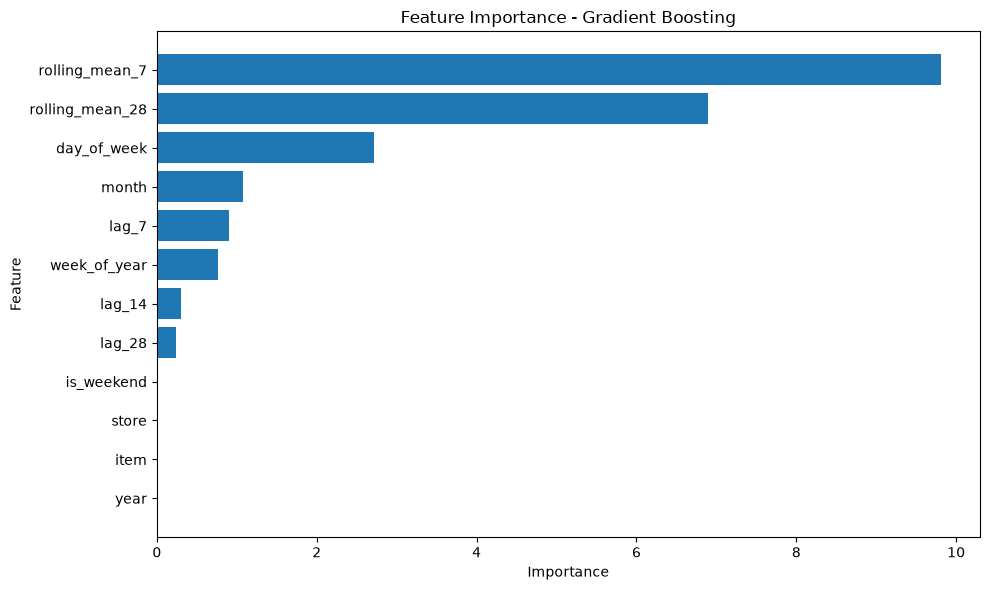

In [188]:
# plot feature importance
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance - Gradient Boosting")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 16. Forecast Evaluation

Compare actual sales with predicted sales to understand how accurately the selected model forecasts demand.

In [189]:
# compare actual and predicted sales
comparison_df = pd.DataFrame({
    "Actual Sales": y_valid,
    "Predicted Sales": gb_predictions
})

display(comparison_df.head(10).round(2))

,Actual Sales,Predicted Sales
1461,19,20.48
1462,15,13.03
1463,10,14.91
1464,16,14.91
1465,14,16.48
1466,24,16.96
1467,14,16.86
1468,20,19.39
1469,18,13.12
1470,11,15.71


### 16.1 Actual vs Predicted Sales

Visualize actual and predicted demand over a sample period to assess how closely the model follows sales patterns.

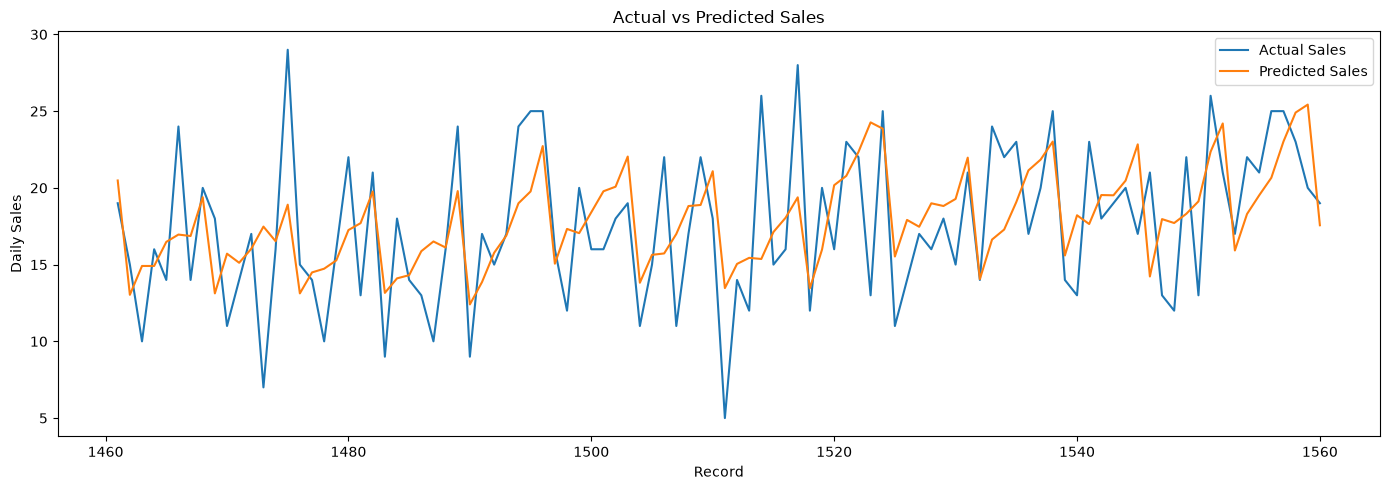

In [190]:
# compare actual and predicted sales
plot_df = comparison_df.head(100).copy()

plt.figure(figsize=(14, 5))
plt.plot(plot_df.index, plot_df["Actual Sales"], label="Actual Sales")
plt.plot(plot_df.index, plot_df["Predicted Sales"], label="Predicted Sales")
plt.xlabel("Record")
plt.ylabel("Daily Sales")
plt.title("Actual vs Predicted Sales")
plt.legend()
plt.tight_layout()
plt.show()

## 17. Inventory Planning

Use forecasted demand, supplier lead time, and current stock to calculate safety stock, reorder points, and suggested reorder quantities.

### 17.1 Inventory Planning Assumptions

The dataset contains historical sales but does not include inventory levels or supplier lead times. These values will be provided as inputs for scenario-based inventory recommendations.

In [191]:
# set inventory planning inputs
lead_time = 7
current_stock = 100
coverage_days = 14
service_level_z = 1.65

In [192]:
# calculate demand and inventory requirements
daily_demand = gb_predictions.mean()
daily_demand_std = y_valid.std()

safety_stock = service_level_z * daily_demand_std * np.sqrt(lead_time)
reorder_point = (daily_demand * lead_time) + safety_stock
target_stock = daily_demand * (lead_time + coverage_days) + safety_stock

reorder_quantity = max(0, target_stock - current_stock)

print(f"Average daily demand: {daily_demand:.2f}")
print(f"Safety stock: {safety_stock:.2f}")
print(f"Reorder point: {reorder_point:.2f}")
print(f"Current stock: {current_stock}")
print(f"Suggested reorder quantity: {np.ceil(reorder_quantity):.0f}")

Average daily demand: 58.80
Safety stock: 137.74
Reorder point: 549.34
Current stock: 100
Suggested reorder quantity: 1273


### 17.2 Product-Level Inventory Planning

Calculate average demand and demand variability separately for each store and item combination to generate more meaningful inventory recommendations.

In [193]:
# prepare product-level demand
inventory_df = valid_data[["store", "item", "sales"]].copy()

inventory_df["predicted_sales"] = gb_predictions

inventory_summary = inventory_df.groupby(
    ["store", "item"]
).agg(
    avg_daily_demand=("predicted_sales", "mean"),
    demand_std=("sales", "std")
).reset_index()

display(inventory_summary.head(10).round(2))

,store,item,avg_daily_demand,demand_std
0,1,1,22.31,6.95
1,1,2,59.72,15.98
2,1,3,37.52,10.52
3,1,4,22.27,6.84
4,1,5,18.95,5.71
5,1,6,59.88,14.83
6,1,7,59.06,15.27
7,1,8,78.50,19.66
8,1,9,52.03,13.12
9,1,10,75.32,18.80


### 17.3 Safety Stock and Reorder Point

Calculate safety stock to protect against demand variability and determine the reorder point using supplier lead time.

In [194]:
# calculate inventory requirements
lead_time = 7
service_level_z = 1.65
coverage_days = 14

inventory_summary["safety_stock"] = (
    service_level_z
    * inventory_summary["demand_std"]
    * np.sqrt(lead_time)
)

inventory_summary["reorder_point"] = (
    inventory_summary["avg_daily_demand"] * lead_time
    + inventory_summary["safety_stock"]
)

inventory_summary["target_stock"] = (
    inventory_summary["avg_daily_demand"] * (lead_time + coverage_days)
    + inventory_summary["safety_stock"]
)

display(inventory_summary.head(10).round(2))

,store,item,avg_daily_demand,demand_std,safety_stock,reorder_point,target_stock
0,1,1,22.31,6.95,30.35,186.55,498.94
1,1,2,59.72,15.98,69.75,487.78,1323.85
2,1,3,37.52,10.52,45.92,308.53,833.77
3,1,4,22.27,6.84,29.85,185.78,497.63
4,1,5,18.95,5.71,24.95,157.59,422.86
5,1,6,59.88,14.83,64.72,483.89,1322.21
6,1,7,59.06,15.27,66.65,480.09,1306.96
7,1,8,78.50,19.66,85.84,635.34,1734.34
8,1,9,52.03,13.12,57.29,421.47,1149.84
9,1,10,75.32,18.80,82.08,609.31,1663.77


### 17.4 Reorder Quantity Calculation

Use simulated current stock levels to calculate suggested replenishment quantities for each store-item combination.

In [195]:
# simulate current stock levels
np.random.seed(42)

inventory_summary["current_stock"] = np.random.randint(
    50, 1500, size=len(inventory_summary)
)

inventory_summary["reorder_quantity"] = np.ceil(
    np.maximum(
        0,
        inventory_summary["target_stock"]
        - inventory_summary["current_stock"]
    )
)

inventory_summary["stock_status"] = np.where(
    inventory_summary["current_stock"]
    <= inventory_summary["reorder_point"],
    "Reorder Required",
    "Stock Sufficient"
)

display(
    inventory_summary[
        [
            "store", "item", "current_stock",
            "reorder_point", "target_stock",
            "reorder_quantity", "stock_status"
        ]
    ].head(10).round(2)
)

,store,item,current_stock,reorder_point,target_stock,reorder_quantity,stock_status
0,1,1,1176,186.55,498.94,0.0,Stock Sufficient
1,1,2,910,487.78,1323.85,414.0,Stock Sufficient
2,1,3,1344,308.53,833.77,0.0,Stock Sufficient
3,1,4,1180,185.78,497.63,0.0,Stock Sufficient
4,1,5,1145,157.59,422.86,0.0,Stock Sufficient
5,1,6,1094,483.89,1322.21,229.0,Stock Sufficient
6,1,7,171,480.09,1306.96,1136.0,Reorder Required
7,1,8,516,635.34,1734.34,1219.0,Reorder Required
8,1,9,1288,421.47,1149.84,0.0,Stock Sufficient
9,1,10,380,609.31,1663.77,1284.0,Reorder Required


### 17.5 Inventory Summary

Summarize stock availability and identify store-item combinations that require replenishment.

In [196]:
# summarize inventory status
status_summary = inventory_summary["stock_status"].value_counts()

print("Total store-item combinations:", len(inventory_summary))
print("Reorder required:", status_summary.get("Reorder Required", 0))
print("Stock sufficient:", status_summary.get("Stock Sufficient", 0))
print("Total units to reorder:", inventory_summary["reorder_quantity"].sum())

Total store-item combinations: 500
Reorder required: 132
Stock sufficient: 368
Total units to reorder: 295550.0


### 17.6 Inventory Replenishment Priorities

Rank store-item combinations by suggested reorder quantity to identify the highest replenishment requirements.

In [197]:
# identify highest replenishment requirements
priority_df = inventory_summary[
    inventory_summary["reorder_quantity"] > 0
].sort_values(
    "reorder_quantity",
    ascending=False
)

display(
    priority_df[
        [
            "store", "item", "current_stock",
            "reorder_point", "reorder_quantity",
            "stock_status"
        ]
    ].head(15).round(2)
)

,store,item,current_stock,reorder_point,reorder_quantity,stock_status
64,2,15,84,985.41,2610.0,Reorder Required
77,2,28,251,986.55,2441.0,Reorder Required
357,8,8,67,862.51,2296.0,Reorder Required
59,2,10,141,855.37,2198.0,Reorder Required
477,10,28,267,886.45,2163.0,Reorder Required
87,2,38,387,924.97,2147.0,Reorder Required
462,10,13,203,853.58,2137.0,Reorder Required
124,3,25,148,830.06,2127.0,Reorder Required
94,2,45,429,929.19,2112.0,Reorder Required
85,2,36,345,889.62,2096.0,Reorder Required


In [198]:
# identify highest replenishment requirements
priority_df = inventory_summary[
    inventory_summary["reorder_quantity"] > 0
].sort_values(
    "reorder_quantity",
    ascending=False
)

display(
    priority_df[
        [
            "store", "item", "current_stock",
            "reorder_point", "reorder_quantity",
            "stock_status"
        ]
    ].head(15).round(2)
)

,store,item,current_stock,reorder_point,reorder_quantity,stock_status
64,2,15,84,985.41,2610.0,Reorder Required
77,2,28,251,986.55,2441.0,Reorder Required
357,8,8,67,862.51,2296.0,Reorder Required
59,2,10,141,855.37,2198.0,Reorder Required
477,10,28,267,886.45,2163.0,Reorder Required
87,2,38,387,924.97,2147.0,Reorder Required
462,10,13,203,853.58,2137.0,Reorder Required
124,3,25,148,830.06,2127.0,Reorder Required
94,2,45,429,929.19,2112.0,Reorder Required
85,2,36,345,889.62,2096.0,Reorder Required


## 18. Inventory Visualization

Visualize inventory health and replenishment requirements across all store-item combinations.

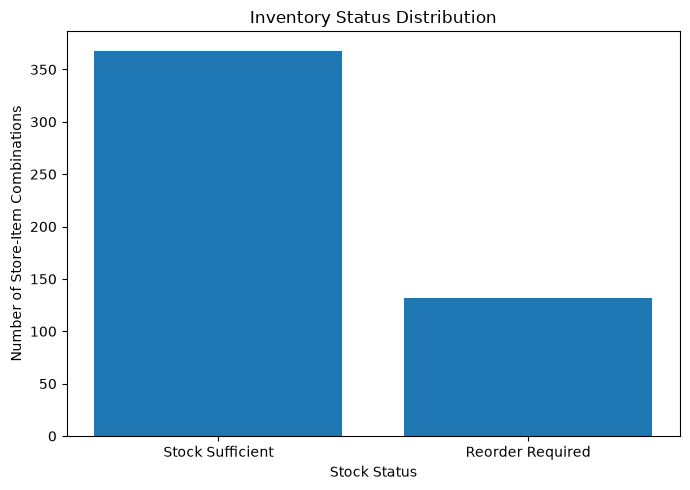

In [199]:
# plot inventory status
status_counts = inventory_summary["stock_status"].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(status_counts.index, status_counts.values)
plt.title("Inventory Status Distribution")
plt.xlabel("Stock Status")
plt.ylabel("Number of Store-Item Combinations")
plt.tight_layout()
plt.show()

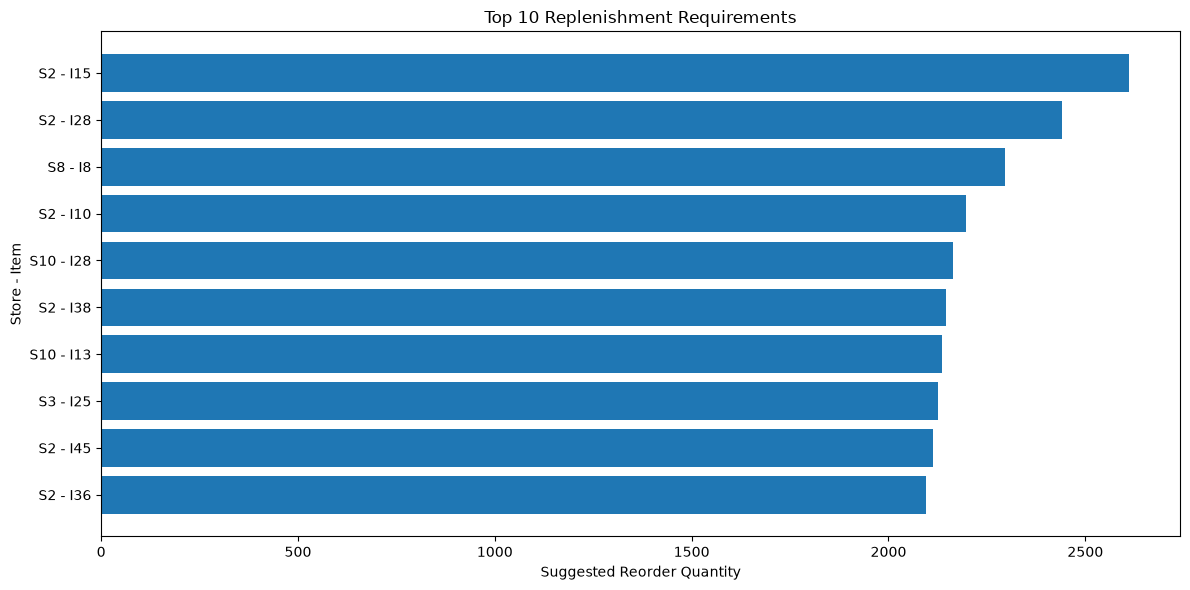

In [200]:
# plot top replenishment requirements
top_priority = priority_df.head(10).copy()
top_priority["store_item"] = (
    "S" + top_priority["store"].astype(str)
    + " - I" + top_priority["item"].astype(str)
)

plt.figure(figsize=(12, 6))
plt.barh(
    top_priority["store_item"],
    top_priority["reorder_quantity"]
)
plt.xlabel("Suggested Reorder Quantity")
plt.ylabel("Store - Item")
plt.title("Top 10 Replenishment Requirements")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 19. Business Insights and Key Findings

### Demand Forecasting
- Gradient Boosting achieved the lowest MAE and RMSE among the three models tested.
- Recent rolling sales averages were the most influential forecasting features.
- Weekly and monthly patterns showed variations in customer demand.

### Inventory Intelligence
- Inventory requirements were calculated separately for each store-item combination.
- Safety stock and reorder points were estimated using demand variability and assumed supplier lead time.
- Replenishment priorities were identified using simulated current stock levels.

### Business Value
The project combines historical sales analysis, machine learning-based demand forecasting, and inventory planning to support better replenishment decisions.

All inventory recommendations are scenario-based because actual inventory and supplier data are not available in the dataset.

### 20. Historical Demand Variability

Calculate demand variability using training-period sales data to avoid using validation-period information in inventory planning.

In [201]:
# calculate historical demand variability
historical_std = train_data.groupby(
    ["store", "item"]
)["sales"].std().reset_index(name="demand_std")

inventory_summary = inventory_summary.drop(
    columns=["demand_std"]
).merge(
    historical_std,
    on=["store", "item"],
    how="left"
)

display(inventory_summary.head(10).round(2))

,store,item,avg_daily_demand,safety_stock,reorder_point,target_stock,current_stock,reorder_quantity,stock_status,demand_std
0,1,1,22.31,30.35,186.55,498.94,1176,0.0,Stock Sufficient,6.51
1,1,2,59.72,69.75,487.78,1323.85,910,414.0,Stock Sufficient,14.04
2,1,3,37.52,45.92,308.53,833.77,1344,0.0,Stock Sufficient,9.54
3,1,4,22.27,29.85,185.78,497.63,1180,0.0,Stock Sufficient,6.41
4,1,5,18.95,24.95,157.59,422.86,1145,0.0,Stock Sufficient,5.49
5,1,6,59.88,64.72,483.89,1322.21,1094,229.0,Stock Sufficient,14.14
6,1,7,59.06,66.65,480.09,1306.96,171,1136.0,Reorder Required,14.42
7,1,8,78.50,85.84,635.34,1734.34,516,1219.0,Reorder Required,17.57
8,1,9,52.03,57.29,421.47,1149.84,1288,0.0,Stock Sufficient,12.74
9,1,10,75.32,82.08,609.31,1663.77,380,1284.0,Reorder Required,17.16


In [202]:
# update inventory recommendations
inventory_summary["safety_stock"] = (
    service_level_z
    * inventory_summary["demand_std"]
    * np.sqrt(lead_time)
)

inventory_summary["reorder_point"] = (
    inventory_summary["avg_daily_demand"] * lead_time
    + inventory_summary["safety_stock"]
)

inventory_summary["target_stock"] = (
    inventory_summary["avg_daily_demand"] * (lead_time + coverage_days)
    + inventory_summary["safety_stock"]
)

inventory_summary["reorder_quantity"] = np.ceil(
    np.maximum(
        0,
        inventory_summary["target_stock"]
        - inventory_summary["current_stock"]
    )
)

inventory_summary["stock_status"] = np.where(
    inventory_summary["current_stock"]
    <= inventory_summary["reorder_point"],
    "Reorder Required",
    "Stock Sufficient"
)

display(inventory_summary.head(10).round(2))

,store,item,avg_daily_demand,safety_stock,reorder_point,target_stock,current_stock,reorder_quantity,stock_status,demand_std
0,1,1,22.31,28.42,184.61,497.01,1176,0.0,Stock Sufficient,6.51
1,1,2,59.72,61.31,479.34,1315.41,910,406.0,Stock Sufficient,14.04
2,1,3,37.52,41.64,304.26,829.49,1344,0.0,Stock Sufficient,9.54
3,1,4,22.27,27.96,183.89,495.74,1180,0.0,Stock Sufficient,6.41
4,1,5,18.95,23.95,156.59,421.86,1145,0.0,Stock Sufficient,5.49
5,1,6,59.88,61.75,480.91,1319.24,1094,226.0,Stock Sufficient,14.14
6,1,7,59.06,62.93,476.37,1303.24,171,1133.0,Reorder Required,14.42
7,1,8,78.50,76.71,626.21,1725.22,516,1210.0,Reorder Required,17.57
8,1,9,52.03,55.61,419.79,1148.16,1288,0.0,Stock Sufficient,12.74
9,1,10,75.32,74.90,602.13,1656.58,380,1277.0,Reorder Required,17.16


In [203]:
# update inventory summary
status_summary = inventory_summary["stock_status"].value_counts()

print("Total combinations:", len(inventory_summary))
print("Reorder required:", status_summary.get("Reorder Required", 0))
print("Stock sufficient:", status_summary.get("Stock Sufficient", 0))
print("Total suggested reorder units:", inventory_summary["reorder_quantity"].sum())

Total combinations: 500
Reorder required: 130
Stock sufficient: 370
Total suggested reorder units: 293483.0


In [204]:
# update replenishment priorities
priority_df = inventory_summary[
    inventory_summary["reorder_quantity"] > 0
].sort_values(
    "reorder_quantity",
    ascending=False
)

display(priority_df.head(15).round(2))

,store,item,avg_daily_demand,safety_stock,reorder_point,target_stock,current_stock,reorder_quantity,stock_status,demand_std
64,2,15,121.98,122.56,976.44,2684.21,84,2601.0,Reorder Required,28.07
77,2,28,121.80,120.92,973.52,2678.73,251,2428.0,Reorder Required,27.70
357,8,8,107.14,104.30,854.26,2354.18,67,2288.0,Reorder Required,23.89
59,2,10,105.95,102.21,843.88,2327.22,141,2187.0,Reorder Required,23.41
477,10,28,110.22,108.26,879.79,2422.85,267,2156.0,Reorder Required,24.80
87,2,38,114.88,111.37,915.52,2523.82,387,2137.0,Reorder Required,25.51
462,10,13,106.15,103.00,846.02,2332.06,203,2130.0,Reorder Required,23.59
124,3,25,103.15,99.36,821.42,2265.55,148,2118.0,Reorder Required,22.76
94,2,45,115.11,111.69,917.49,2529.10,429,2101.0,Reorder Required,25.58
85,2,36,110.76,107.23,882.55,2433.18,345,2089.0,Reorder Required,24.56


### 20.1 Inventory Calculation Validation

Validate inventory calculations and check for missing values, negative quantities, and inconsistent stock classifications.

In [205]:
# validate inventory calculations
print("Missing values:", inventory_summary.isnull().sum().sum())

print(
    "Negative reorder quantities:",
    (inventory_summary["reorder_quantity"] < 0).sum()
)

print(
    "Invalid reorder points:",
    (inventory_summary["reorder_point"] < 0).sum()
)

print(
    "Incorrect stock classifications:",
    (
        inventory_summary["stock_status"]
        != np.where(
            inventory_summary["current_stock"]
            <= inventory_summary["reorder_point"],
            "Reorder Required",
            "Stock Sufficient"
        )
    ).sum()
)

print(
    "Unique store-item combinations:",
    inventory_summary[["store", "item"]].drop_duplicates().shape[0]
)

Missing values: 0
Negative reorder quantities: 0
Invalid reorder points: 0
Incorrect stock classifications: 0
Unique store-item combinations: 500


## 21. Conclusion

This project developed a retail demand forecasting and inventory intelligence workflow using historical sales data from 10 stores and 50 items.

The analysis covered data cleaning, exploratory analysis, feature engineering, machine learning, model evaluation, and inventory planning.

Three forecasting approaches were evaluated:
- Baseline forecasting
- Random Forest
- HistGradientBoosting

HistGradientBoosting achieved the best validation performance among the tested models, with an MAE of 6.17 and RMSE of 8.02.

The selected forecasting model was combined with inventory planning calculations to estimate safety stock, reorder points, target stock levels, and replenishment quantities for individual store-item combinations.

### Project Limitations
- Inventory levels were simulated because actual stock data was unavailable.
- Supplier lead time and service-level parameters were assumed.
- Forecast evaluation used a rolling one-step-ahead approach.
- Recommendations are planning estimates, not actual purchasing instructions.

### Future Improvements
- Integrate real-time inventory and supplier data.
- Evaluate additional forecasting approaches.
- Incorporate product-specific lead times.
- Deploy the workflow as an interactive dashboard.